# Lesson 8 — Neural networks: why a straight line isn't enough

Lesson 8 — Neural networks: why a straight line isn't enough
============================================================

GURU NOTE
---------
Logistic regression draws ONE straight boundary through feature space. That's
powerful but limited. Some patterns can't be split by any straight line.

The classic example — and it's not abstract for you — is XOR / "combination"
logic: "feature A alone is fine, feature B alone is fine, but A AND B together is
an attack." A quoted string is normal. A SQL keyword is normal. Both in the same
parameter is suspicious. Your repo even has a `combo` feature for exactly this.
No single straight line can carve out "exactly one of A/B, but not both."

The fix is a NEURAL NETWORK (a multi-layer perceptron, MLP): stack a second layer
with a nonlinearity (ReLU) in between. The hidden layer bends the space so the
output layer CAN separate it with a line. This lesson shows a straight-line model
failing, then a tiny hand-built MLP succeeding, so you SEE what the hidden layer
buys you. Lesson 9 makes it LEARN those hidden weights.

Run me:  python lessons/lesson_08_neural_networks.py

## Setup

These notebooks *import* the real code from `lessons/*.py` — one source of truth, no forked copies. This cell finds that folder.

In [1]:
import sys, pathlib
for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (base / 'lessons' / '_util.py').exists():
        sys.path.insert(0, str(base / 'lessons'))
        print('lessons on path:', base / 'lessons'); break
else:
    raise RuntimeError('Open this notebook inside the xorguard-ml-course folder.')

lessons on path: /Users/anil/Documents/developer/vscodeworkspaces/xordev/xorguard-ml-course/lessons


## The key code (shown live from the source file)

Read it, then copy any function into a new cell and tweak it — the originals live in `lessons/lesson_08_neural_networks.py`.

In [2]:
import inspect
from lesson_08_neural_networks import relu, forward
for fn in (relu, forward):
    print(inspect.getsource(fn)); print('-' * 72)

def relu(z):
    return np.maximum(z, 0.0)

------------------------------------------------------------------------
def forward(x, w1, b1, w2, b2):
    """A 2-layer MLP forward pass. IDENTICAL to neural.forward in your repo.

    Step 1 (hidden layer): h = relu(x @ w1.T + b1)   -- bends the space
    Step 2 (output layer): p = sigmoid(h @ w2.T + b2) -- draws the line
    Shapes: w1 (hidden,d)  b1 (hidden,)  w2 (1,hidden)  b2 (1,)
    """
    h = relu(x @ w1.T + b1)
    return sigmoid((h @ w2.T + b2).ravel())

------------------------------------------------------------------------


## A picture

A real plot (matplotlib) in place of the terminal's ASCII. Re-run after changing inputs to build intuition.

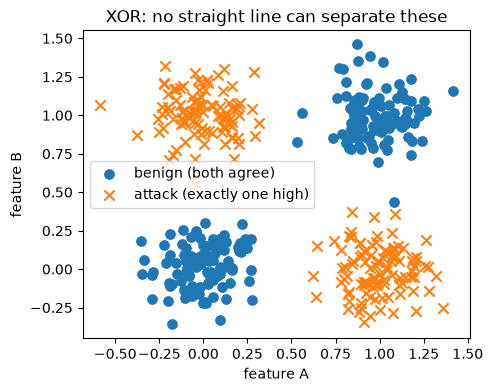

In [3]:
import matplotlib.pyplot as plt
from lesson_08_neural_networks import make_xor
X, y = make_xor()
plt.figure(figsize=(5, 4))
plt.scatter(X[y == 0, 0], X[y == 0, 1], marker='o', s=45, label='benign (both agree)')
plt.scatter(X[y == 1, 0], X[y == 1, 1], marker='x', s=55, label='attack (exactly one high)')
plt.xlabel('feature A'); plt.ylabel('feature B')
plt.title('XOR: no straight line can separate these'); plt.legend(); plt.show()

## Run the full narrated lesson

This executes the same walkthrough as `python lessons/lesson_08_neural_networks.py`, printing each step with its result.

In [4]:
from lesson_08_neural_networks import main
main()


════════════════════════════════════════════════════════════
Lesson 8 — Neural networks: why a straight line isn't enough
════════════════════════════════════════════════════════════

▸ The data: 'attack only in COMBINATION'. Look at the four clusters.
    benign  '.' sit at (0,0) and (1,1)  — both features agree
    attack  '#' sit at (0,1) and (1,0)  — exactly one feature high

   feature B ↑   ( # = malicious   . = benign )
      |                                        . . .           
      |         ## # ### ###   #            ..  .    . .       
      |#        #### ######## #            . ... .........    .
      |         ######## ####  #      .       ............     
      |     #   # # ##### ###  #     .     .........   . .     
      |          ##  #     #                      .    .       
      |              #                                         
      |                                       #  #  #          
      |          . . ...  .  .               ##   # #   

## Exercises

Try these in new cells below. Worked answers are in `solutions/lesson_08_solution.py`.

```
1. Break the MLP: change b2 from -3.0 to +3.0 and re-run. Why does accuracy
   collapse? (You moved the baseline so everything reads as an attack.)

2. The hidden layer is doing the work. Print h = relu(X @ w1.T + b1) for one
   attack point and one benign point. Confirm h2 (the second column) only lights
   up for both-high inputs.

3. Can ONE hidden unit solve XOR? Try w1 with shape (1,2) and a matching w2.
   Convince yourself (and explain in a comment) why you need at least two.
```

In [5]:
# your work here
